In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pymannkendall as mk


In [2]:

csv_file = r"C:\Users\RUTHVIK REDDY\lulc_project\NDVI results\NDVI Results - Sheet1.csv"

df = pd.read_csv(csv_file)

df = df.sort_values("Year").reset_index(drop=True)

zones = {
    "0–1 km Zone": "0_1_Zone_mean",
    "1–3 km Zone": "1_3_Zone_mean",
    "3–5 km Zone": "3_5_Zone_mean"
}

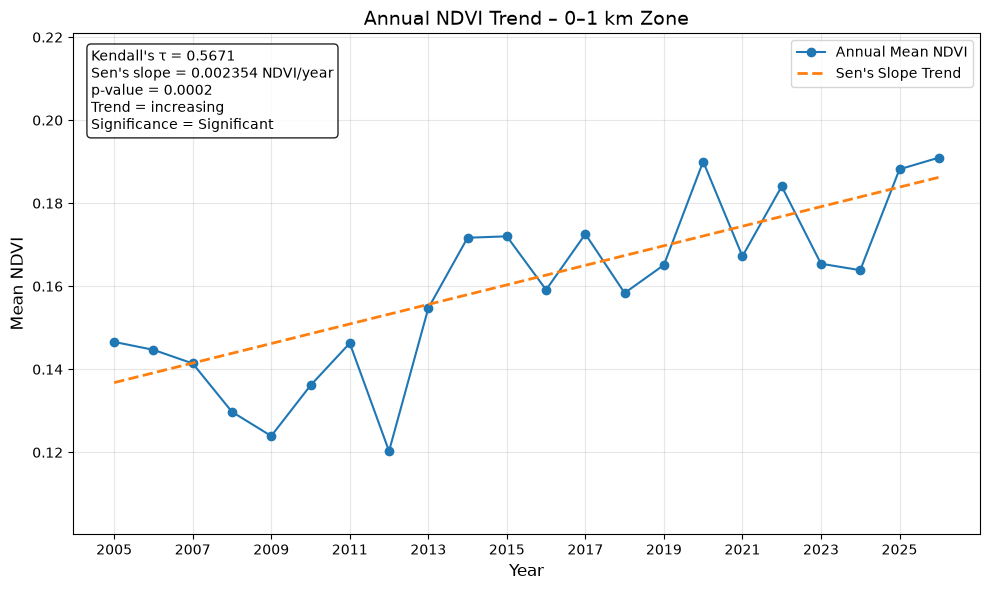

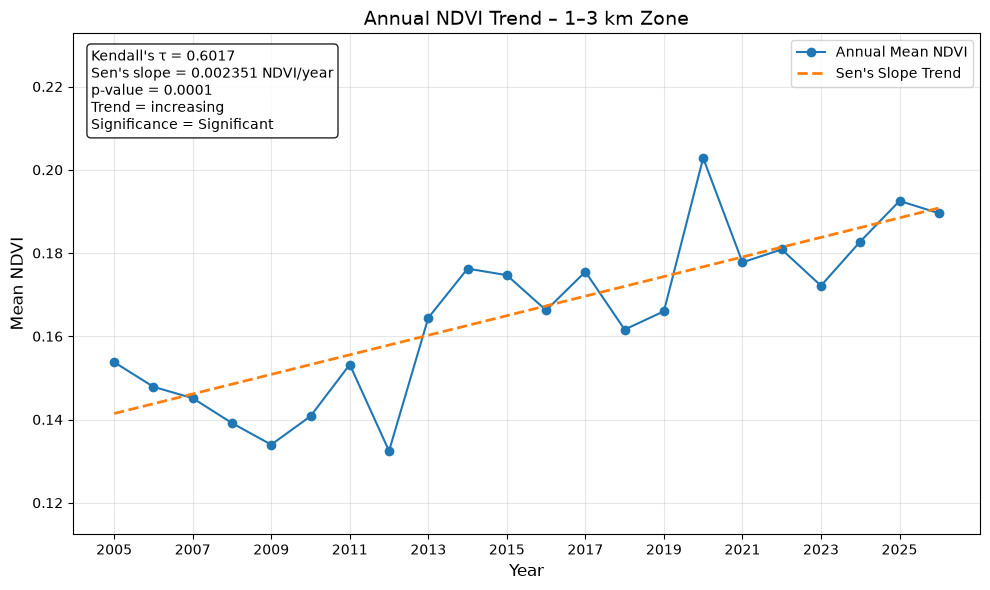

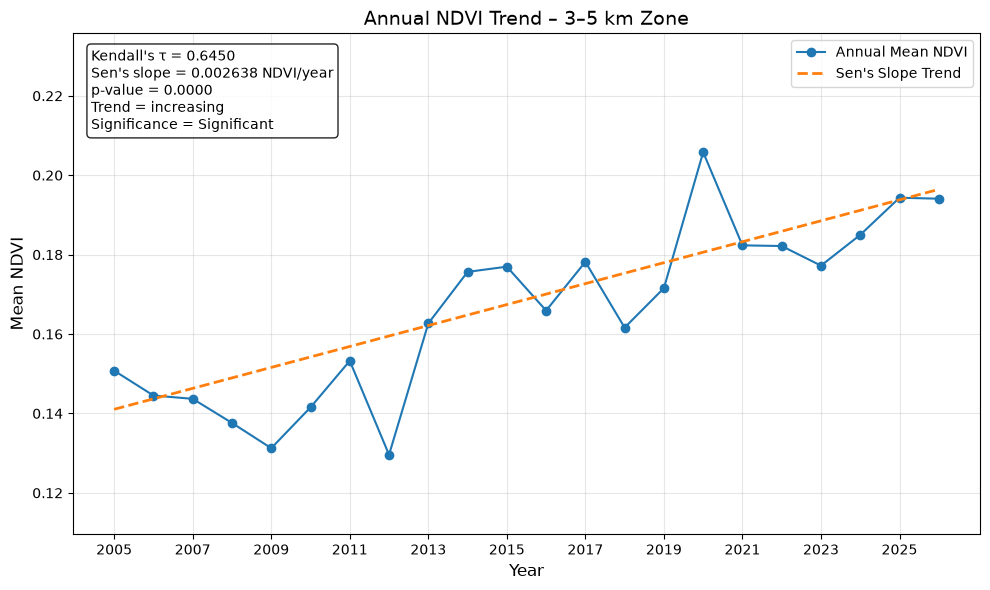

In [3]:
for zone_name, column in zones.items():

    data = df[["Year", column]].dropna()

    years = data["Year"].to_numpy()
    ndvi = data[column].to_numpy()

    # Mann-Kendall test
    result = mk.original_test(ndvi)

    # Sen's slope
    sen_slope = result.slope

    trend_line = (
        np.median(ndvi)
        + sen_slope * (years - np.median(years))
    )


    plt.figure(figsize=(10, 6))

    plt.plot(
        years,
        ndvi,
        marker="o",
        linewidth=1.5,
        label="Annual Mean NDVI"
    )

    plt.plot(
        years,
        trend_line,
        linestyle="--",
        linewidth=2,
        label="Sen's Slope Trend"
    )

    plt.xlabel("Year", fontsize=12)
    plt.ylabel("Mean NDVI", fontsize=12)

    plt.title(
        f"Annual NDVI Trend – {zone_name}",
        fontsize=14
    )


    if result.p < 0.05:
        significance = "Significant"
    else:
        significance = "Not significant"

    text = (
        f"Kendall's τ = {result.Tau:.4f}\n"
        f"Sen's slope = {sen_slope:.6f} NDVI/year\n"
        f"p-value = {result.p:.4f}\n"
        f"Trend = {result.trend}\n"
        f"Significance = {significance}"
    )

    plt.text(
        0.02,
        0.97,
        text,
        transform=plt.gca().transAxes,
        verticalalignment="top",
        fontsize=10,
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            alpha=0.85
        )
    )

    plt.xticks(
        np.arange(
            years.min(),
            years.max() + 1,
            2
        )
    )

    plt.ylim(
        max(0, ndvi.min() - 0.02),
        ndvi.max() + 0.03
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plt.show()


0–1 km Zone
Kendall's Tau: 0.5671
Sen's slope: 0.002354 NDVI/year
p-value: 0.000247
Trend: increasing
Significance: Significant

1–3 km Zone
Kendall's Tau: 0.6017
Sen's slope: 0.002351 NDVI/year
p-value: 0.000100
Trend: increasing
Significance: Significant

3–5 km Zone
Kendall's Tau: 0.6450
Sen's slope: 0.002638 NDVI/year
p-value: 0.000030
Trend: increasing
Significance: Significant


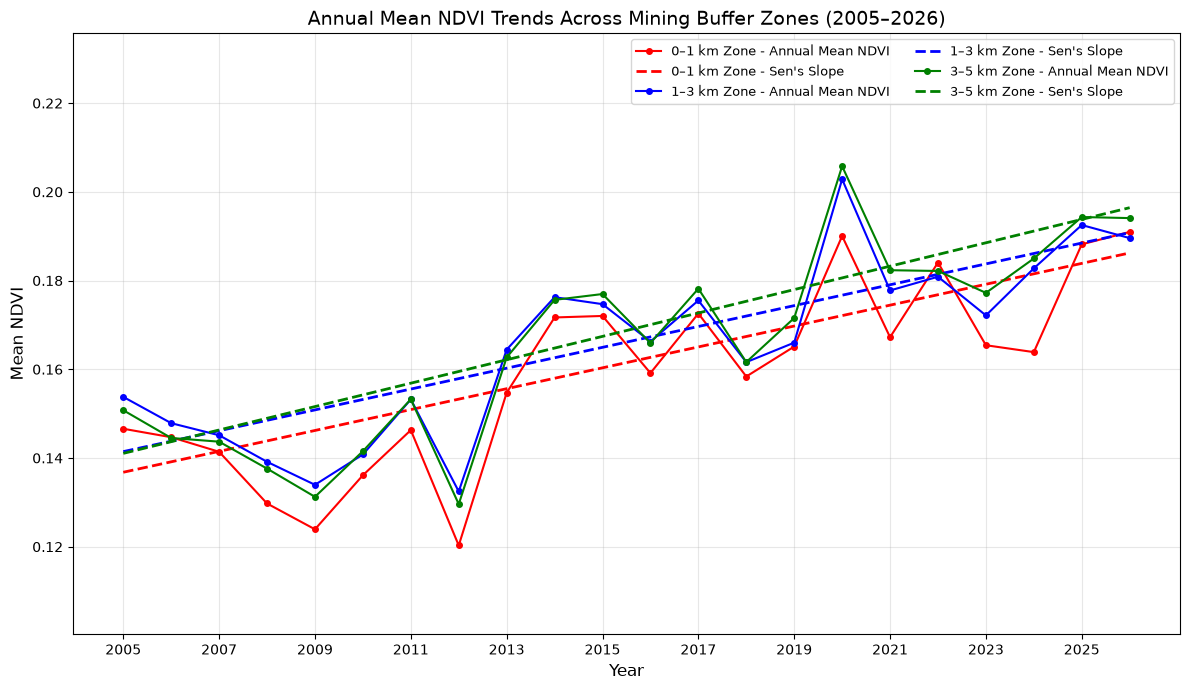

In [4]:
plt.figure(figsize=(12, 7))

# Different colours for the three zones
colors = {
    "0–1 km Zone": "red",
    "1–3 km Zone": "blue",
    "3–5 km Zone": "green"
}

for zone_name, column in zones.items():

    data = df[["Year", column]].dropna()

    years = data["Year"].to_numpy()
    ndvi = data[column].to_numpy()

    # Mann-Kendall test
    result = mk.original_test(ndvi)

    # Sen's slope
    sen_slope = result.slope

    # Calculate trend line
    trend_line = (
        np.median(ndvi)
        + sen_slope * (years - np.median(years))
    )

    color = colors[zone_name]

    # Plot annual mean NDVI
    plt.plot(
        years,
        ndvi,
        marker="o",
        color=color,
        linewidth=1.5,
        markersize=4,
        label=f"{zone_name} - Annual Mean NDVI"
    )

    # Plot Sen's slope trend line
    plt.plot(
        years,
        trend_line,
        linestyle="--",
        color=color,
        linewidth=2,
        label=f"{zone_name} - Sen's Slope"
    )

    # Print statistical results for each zone
    significance = (
        "Significant" if result.p < 0.05
        else "Not significant"
    )

    print(f"\n{zone_name}")
    print(f"Kendall's Tau: {result.Tau:.4f}")
    print(f"Sen's slope: {sen_slope:.6f} NDVI/year")
    print(f"p-value: {result.p:.6f}")
    print(f"Trend: {result.trend}")
    print(f"Significance: {significance}")

# Graph formatting
plt.xlabel("Year", fontsize=12)
plt.ylabel("Mean NDVI", fontsize=12)

plt.title(
    "Annual Mean NDVI Trends Across Mining Buffer Zones (2005–2026)",
    fontsize=14
)

plt.xticks(
    np.arange(
        df["Year"].min(),
        df["Year"].max() + 1,
        2
    )
)

plt.ylim(
    max(0, df[list(zones.values())].min().min() - 0.02),
    df[list(zones.values())].max().max() + 0.03
)

plt.grid(True, alpha=0.3)
plt.legend(fontsize=9, ncol=2)
plt.tight_layout()
plt.show()